# 1.2 - Exploración básica de variables (`accidentes.csv`)

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/accidentes.csv")

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(2062, 21)


,fecha,hora,numero_incidencia,localizacion,ubicacion,carretera,eje,tipo_via,tipo_accidente,tipo_colision,...,motos_implicadas,pesados_implicados,estado_firme,circulacion,heridos_leves,heridos_graves,victimas_mortales,descripcion,distrito,unidad_samur_id
0,01/01/2024 0:00,1:30:48,20240101-0001,08NL10,SUPERFICIE,M30,NL,VIA DE SERVICIO,Colision entre vehiculos,COLISIÓN POR ALCANCE,...,0,0,Seco y limpio,NaN,1,0,0,SEÑALIZAR ACCIDENTE POR ALCANCE EN CARRIL CENT...,CENTRO,49.0
1,01/01/2024 0:00,1:59:17,20240101-0002,07NC10,SUPERFICIE,M30,NC,Via de Servicio,Colision entre vehiculos,COLISIÓN POR ALCANCE,...,0,0,seco,FLUIDA,0,0,0,"AVISO DE ALCANCE ENTRE 2 VEHÍCULOS, ANTES DE L...",USERA,NaN
2,01/01/2024 0:00,5:58:11,20240101-0007,03FT45,TÚNEL,A5,FT,TRONCO,Colision entre vehiculos,COLISIÓN POR ALCANCE,...,0,0,Seco y limpio,FLUIDA,0,0,0,ACCIDENTE LEVE ENTRE DOS VEHICULOS (ALCANCE) E...,VICALVARO,29.0
3,01/02/2024,9:51:53,20240102-0009,30RJ10,SUPERFICIE,M30,30RJ,RAMAL,Salida de via,COLISIÓN MEDIANA,...,0,0,Seco y limpio,FLUIDA,0,0,0,"ACCIDENTE LEVE SIN HERIDOS,EL VEHÍCULO CHOCA C...",RETIRO,NaN
4,02/01/2024 0:00,18:14:56,20240102-0022,11NL00,SUPERFICIE,M30,NL,VIA DE SERVICIO,Colision entre vehiculos,COLISIÓN POR ALCANCE,...,0,0,Seco y limpio,DENSA,0,0,0,SEÑALIZAR COLISIÓN POR ALCANCE ENTRE DOS VEHÍC...,ARGANZUELA,50.0


## Schema and types

In [2]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (100 * df.isna().mean()).round(2),
    "nunique": df.nunique(dropna=False),
})
info

,dtype,n_missing,pct_missing,nunique
fecha,object,0,0.00,443
hora,object,0,0.00,1939
numero_incidencia,object,0,0.00,1962
localizacion,object,0,0.00,1067
ubicacion,object,0,0.00,2
carretera,object,1,0.05,14
eje,object,0,0.00,171
tipo_via,object,0,0.00,12
tipo_accidente,object,0,0.00,6
tipo_colision,object,80,3.88,6


## Target: severo vs no

severe: 45 / 2062 (2.18%)
heridos_graves>0: 40
victimas_mortales>0: 7


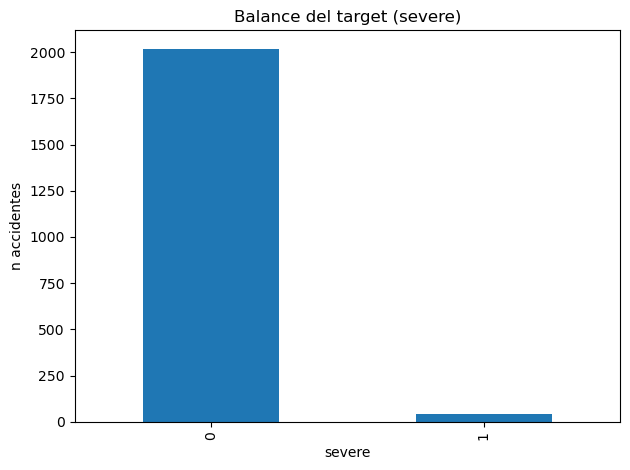

In [3]:
for c in ["heridos_graves", "heridos_leves", "victimas_mortales", "vehiculos_implicados",
          "motos_implicadas", "pesados_implicados"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["severe"] = ((df["heridos_graves"].fillna(0) > 0) | (df["victimas_mortales"].fillna(0) > 0)).astype(int)

n = len(df)
n_sev = int(df["severe"].sum())
print(f"severe: {n_sev} / {n} ({100*n_sev/n:.2f}%)")
print("heridos_graves>0:", int((df["heridos_graves"] > 0).sum()))
print("victimas_mortales>0:", int((df["victimas_mortales"] > 0).sum()))

df["severe"].value_counts().plot(kind="bar", title="Balance del target (severe)")
plt.ylabel("n accidentes")
plt.tight_layout()
plt.show()

## Tiempo: `fecha` y `hora`

fecha parseada: 1962 / 2062
rango: 2024-01-01 00:00:00 → 2024-12-31 00:00:00


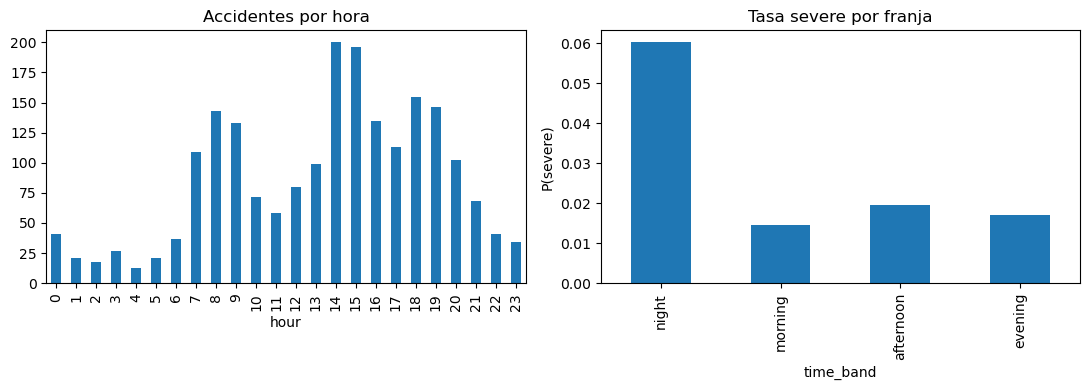

In [4]:
df["fecha_dt"] = pd.to_datetime(df["fecha"], errors="coerce", dayfirst=True)
print("fecha parseada:", df["fecha_dt"].notna().sum(), "/", len(df))
print("rango:", df["fecha_dt"].min(), "→", df["fecha_dt"].max())

hora = pd.to_datetime(df["hora"].astype(str), format="%H:%M:%S", errors="coerce")
if hora.isna().all():
    hora = pd.to_datetime(df["hora"].astype(str), format="%H:%M", errors="coerce")
df["hour"] = hora.dt.hour

def time_band(h):
    if pd.isna(h): return np.nan
    h = int(h)
    if h >= 22 or h < 6: return "night"
    if h < 12: return "morning"
    if h < 18: return "afternoon"
    return "evening"

df["time_band"] = df["hour"].map(time_band)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["hour"].value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Accidentes por hora")
df.groupby("time_band")["severe"].mean().reindex(["night","morning","afternoon","evening"]).plot(
    kind="bar", ax=ax[1], title="Tasa severe por franja")
ax[1].set_ylabel("P(severe)")
plt.tight_layout()
plt.show()

## Categóricas clave (conteos + tasa severe)

In [5]:
CATS = ["tipo_colision", "estado_firme", "tipo_via", "tipo_accidente",
        "ubicacion", "circulacion", "distrito"]

def summarize_cat(col, top=12):
    s = df[col].astype(str).str.strip()
    vc = s.value_counts(dropna=False).head(top)
    rate = df.groupby(s)["severe"].agg(["mean", "count"]).rename(columns={"mean": "severe_rate"})
    rate = rate.loc[vc.index]
    rate["severe_rate"] = (100 * rate["severe_rate"]).round(2)
    print(f"\n=== {col} (top {top}) ===")
    display(rate)

for c in CATS:
    if c in df.columns:
        summarize_cat(c)


=== tipo_colision (top 12) ===


,severe_rate,count
tipo_colision,,
COLISIÓN POR ALCANCE,1.04,1149
Otro,3.82,393
COLISIÓN LATERAL,4.44,315
COLISIÓN MEDIANA,2.17,92
nan,0.00,80
COLISIÓN FRONTAL,6.06,33



=== estado_firme (top 12) ===


,severe_rate,count
estado_firme,,
Seco y limpio,2.53,1618
Mojado,0.00,196
nan,2.00,50
Seco,2.50,40
SECO,2.70,37
seco,0.00,32
Otros,3.12,32
SECO Y LIMPIO,0.00,30
Húmedo,0.00,9



=== tipo_via (top 12) ===


,severe_rate,count
tipo_via,,
TRONCO,1.82,825
VIA DE SERVICIO,2.63,685
RAMAL,2.16,416
Ramal,0.00,20
TRANSFER,0.00,19
TABLERO,0.00,17
Via de Servicio,6.25,16
Transfer,0.00,15
tronco,7.14,14


... (4 outputs left out)


=== circulacion (top 12) ===


,severe_rate,count
circulacion,,
FLUIDA,2.48,725
CONGESTIONADA,3.25,646
DENSA,0.67,599
nan,2.67,75
0,0.00,12
_,0.00,5



=== distrito (top 12) ===


,severe_rate,count
distrito,,
HORTALEZA,2.38,126
TETUAN,1.71,117
CARABANCHEL,5.17,116
BARAJAS,1.75,114
SALAMANCA,2.65,113
CENTRO,0.90,111
USERA,2.70,111
LATINA,0.00,110
MONCLOA,1.85,108


## Vehículos: motos / pesados / implicados

In [6]:
df["has_moto"] = (df["motos_implicadas"].fillna(0) >= 1).astype(int)
print(df.groupby("has_moto")["severe"].agg(["count", "mean"]))

for c in ["vehiculos_implicados", "motos_implicadas", "pesados_implicados"]:
    print(f"\n{c} value counts (incl. -1 / NaN):")
    print(df[c].value_counts(dropna=False).head(15))

          count      mean
has_moto                 
0          1677  0.009541
1           385  0.075325

vehiculos_implicados value counts (incl. -1 / NaN):
vehiculos_implicados
 2    1258
 1     441
 3     244
 4      62
 5      20
 0      17
-1      15
 6       4
 8       1
Name: count, dtype: int64

motos_implicadas value counts (incl. -1 / NaN):
motos_implicadas
0    1677
1     378
2       7
Name: count, dtype: int64

pesados_implicados value counts (incl. -1 / NaN):
pesados_implicados
0    1897
1     157
2       8
Name: count, dtype: int64


## Notas rápidas (no usar como inputs)
- No usar `heridos_leves`, `heridos_graves`, `victimas_mortales` como features (leakage).
- `descripcion` → tarea 2.1 RAG.
- IDs de alta cardinalidad: `numero_incidencia`, `localizacion`, `eje`, `unidad_samur_id`.

In [7]:
HIGH_CARD = ["numero_incidencia", "localizacion", "eje", "unidad_samur_id", "carretera"]
for c in HIGH_CARD:
    if c in df.columns:
        print(f"{c}: nunique={df[c].nunique(dropna=False)}, missing={df[c].isna().sum()}")

numero_incidencia: nunique=1962, missing=0
localizacion: nunique=1067, missing=0
eje: nunique=171, missing=0
unidad_samur_id: nunique=51, missing=558
carretera: nunique=14, missing=1
